# Sales Loss Prediction | 03. Features

This notebook builds the variables of the model in three steps:

1. **Order variables:** what we know about the order itself (kit, price, discount, payment, freight).
2. **Customer history:** how this installer behaved in the past (ticket, discount, kit size, price, loss rate).
3. **Time of the order:** the fix of the most important variable of the original model, which had a leakage problem.

The golden rule of the whole notebook is: **a feature can only use information that existed at the moment of the prediction.** It sounds obvious, but steps 2 and 3 show how easy it is to break it without noticing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("ggplot")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 13, "axes.titlesize": 15})

PASTA_DADOS = Path("../data")
DATA_REF = pd.Timestamp("2025-06-30")

itens = pd.read_parquet(PASTA_DADOS / "pedidos_itens.parquet")

## 1. Order variables
The item lines are aggregated by order. Modules and inverters are separated by the unit power (`PotenciakWp`): below 1 kWp it is a module, above 1 kWp it is an inverter.

In [2]:
pot = itens["PotenciakWp"]
qtd = itens["Quantidade"]
itens["p_modulo"] = np.where((pot > 0) & (pot < 1), pot * qtd, np.nan)
itens["p_inversor"] = np.where(pot > 1, pot * qtd, np.nan)

pedidos = (
    itens.groupby(["PedidoId", "NumeroPedido"], as_index=False)
    .agg(
        CpfCnpj                 = ("CpfCnpj", "first"),
        uf_cliente              = ("uf_cliente", "first"),
        Data_Primeira_Compra    = ("Data_Primeira_Compra", "first"),
        DataCriacaoId           = ("DataCriacaoId", "first"),
        DataGanhoPerdaID        = ("DataGanhoPerdaID", "first"),
        Status_Pedido           = ("Status_Pedido", "first"),
        descricao_etapa         = ("descricao_etapa", "first"),
        motivo_perda            = ("motivo_perda", "first"),
        forma_pagamento         = ("forma_pagamento", "first"),
        TipoFrete               = ("TipoFrete", "first"),
        situacao_pedido         = ("situacao_pedido", "first"),
        SubTotal                = ("SubTotal", "sum"),
        Desconto                = ("Desconto", "sum"),
        ValorTotal              = ("ValorTotal", "sum"),
        total_potencia_modulo   = ("p_modulo", "sum"),
        total_potencia_inversor = ("p_inversor", "sum"),
    )
)

# administrative losses are removed, they are not real sales losses
pedidos = pedidos[~pedidos["motivo_perda"].isin(["Pedido duplicado", "Teste"])].reset_index(drop=True)
print(f"{len(pedidos):,} orders")

18,945 orders


Now the order variables. The groupings of payment and discount type are the same ones seen in notebook 02.

In [3]:
AVISTA = {"PIX", "BOLETO A VISTA", "TED", "BOLETO + PIX"}
FINANCIAMENTO = {"FINANCIAMENTO BANCARIO", "FINANCIAMENTO + BOLETO", "FINANCIAMENTO INTERNO"}
CARTAO = {"CARTAO DE CREDITO", "PIX + CARTAO DE CREDITO"}

pedidos["perda"] = np.select([pedidos["Status_Pedido"] == "Perda", pedidos["Status_Pedido"] == "Ganho"], [1.0, 0.0], default=np.nan)
pedidos["tempo_pedido"] = (pedidos["DataGanhoPerdaID"] - pedidos["DataCriacaoId"]).dt.days
pedidos["tempo_cliente_compra"] = (pedidos["DataCriacaoId"] - pedidos["Data_Primeira_Compra"]).dt.days
pedidos["mes"] = pedidos["DataCriacaoId"].dt.month

pedidos["perc_desconto"] = np.where(pedidos["SubTotal"] > 0, pedidos["Desconto"] / pedidos["SubTotal"] * 100, np.nan)
pedidos["potencia_kit"] = pedidos["total_potencia_modulo"]
pedidos["real_por_wat"] = pedidos["ValorTotal"] / pedidos["total_potencia_modulo"] / 1000
pedidos["oversize"] = np.where(pedidos["total_potencia_inversor"] > 0,
                               pedidos["total_potencia_modulo"] / pedidos["total_potencia_inversor"], np.nan)
pedidos["frete_uf"] = pedidos["TipoFrete"] + "_" + pedidos["uf_cliente"]

pedidos["pagamento"] = np.select(
    [pedidos["forma_pagamento"].isin(AVISTA),
     pedidos["forma_pagamento"].isin(FINANCIAMENTO),
     pedidos["forma_pagamento"].isin(CARTAO)],
    ["avista", "financiamento", "cartao_de_credito"],
    default="outros",
)

sp = pedidos["situacao_pedido"]
pdesc = pedidos["perc_desconto"].round(6)
pedidos["tipo_desconto"] = np.select(
    [(pdesc == 0) & sp.isna(), (pdesc == 0) & (sp == "Aprovado"), (pdesc == 0) & (sp == "Reprovado"),
     (pdesc < 0) & sp.isna(), (pdesc < 0) & (sp == "Aprovado"), (pdesc < 0) & (sp == "Reprovado"),
     (pdesc > 0) & sp.isna(), (pdesc > 0) & (sp == "Aprovado"), (pdesc > 0) & (sp == "Reprovado")],
    ["Sem desconto", "Sem desconto - Aprovado", "Sem desconto - Reprovado",
     "Com desconto", "Com desconto - Aprovado", "Com desconto - Reprovado",
     "Com acréscimo", "Com acréscimo - Aprovado", "Com acréscimo - Reprovado"],
    default="Outro",
)

pedidos[["PedidoId", "Status_Pedido", "pagamento", "tipo_desconto", "potencia_kit", "real_por_wat", "oversize", "frete_uf"]].head()

,PedidoId,Status_Pedido,pagamento,tipo_desconto,potencia_kit,real_por_wat,oversize,frete_uf
0,100001,Ganho,financiamento,Sem desconto,9.900,3.391774,1.237500,FOB_MA
1,100002,Perda,avista,Sem desconto,4.270,3.239457,0.854000,FOB_SP
2,100003,Perda,avista,Com desconto,11.305,3.088341,1.413125,FOB_SP
3,100004,Ganho,financiamento,Com acréscimo,12.650,3.194750,1.054167,CIF_BA
4,100005,Ganho,financiamento,Sem desconto,29.700,2.784718,1.188000,CIF_SP


## 2. Customer history
The idea of these variables is to compare the order with the **usual behaviour of the installer**: is this order bigger than usual? more expensive? with a bigger discount? Each comparison becomes a `delta_*` variable.

### The mistake that is easy to make
The original pipeline calculated the history with cumulative sums ordered by the **creation date**, using `shift(1)` so that each order would only "see" the previous ones. It is the classic approach and it looks correct, but it is not. Consider two orders of the same customer:

| Order | Created | Closed |
|-------|---------|--------|
| A | Jan 1 | Jan 30 (won) |
| B | Jan 10 | - |

Order A was created before B, so the cumulative approach counts A as a past **win** in B's history. But on January 10, when B was created, nobody knew yet that A would be won! The outcome of A is information from the future.

### The correct approach: point-in-time
For each order, its history is made **only of the orders of the same customer that were already closed on its creation date**. In pandas this is a self-merge by customer followed by a date filter. With some thousands of orders per customer it would be heavy, but here the volume is small and the code is easy to read.

In [4]:
fechados = pedidos.loc[pedidos["perda"].notna(),
                       ["CpfCnpj", "DataGanhoPerdaID", "perda", "ValorTotal", "perc_desconto", "potencia_kit",
                        "total_potencia_modulo", "total_potencia_inversor", "tempo_pedido"]]

historico = pedidos[["PedidoId", "CpfCnpj", "DataCriacaoId"]].merge(fechados, on="CpfCnpj", suffixes=("", "_h"))
historico = historico[historico["DataGanhoPerdaID"] < historico["DataCriacaoId"]]

print(f"{len(historico):,} pairs (order, past closed order of the same customer)")

187,740 pairs (order, past closed order of the same customer)


With the history in hand, two groups of indicators are calculated:

- **All past closed orders:** how many there are, the historical loss rate and the average time until the outcome.
- **Only the past wins:** the purchase profile of the customer (ticket, discount, kit size, R$/W, oversize and the date of the last purchase).

In [5]:
ind_fechados = (
    historico.groupby("PedidoId", as_index=False)
    .agg(
        n_pedidos_fechados = ("perda", "size"),
        taxa_perda_hist    = ("perda", "mean"),
        media_tempo_pedido = ("tempo_pedido", "mean"),
    )
)

ind_ganhos = (
    historico[historico["perda"] == 0]
    .groupby("PedidoId", as_index=False)
    .agg(
        n_pedidos_ganhos              = ("perda", "size"),
        data_ultima_compra            = ("DataGanhoPerdaID", "max"),
        ticket_medio_integrador       = ("ValorTotal", "mean"),
        desconto_medio_integrador     = ("perc_desconto", "mean"),
        potencia_kit_medio_integrador = ("potencia_kit", "mean"),
        valor_acum                    = ("ValorTotal", "sum"),
        modulo_acum                   = ("total_potencia_modulo", "sum"),
        inversor_acum                 = ("total_potencia_inversor", "sum"),
    )
)
ind_ganhos["real_por_wat_medio"] = ind_ganhos["valor_acum"] / ind_ganhos["modulo_acum"] / 1000
ind_ganhos["oversize_medio_integrador"] = ind_ganhos["modulo_acum"] / ind_ganhos["inversor_acum"]

pedidos = (
    pedidos
    .merge(ind_fechados, on="PedidoId", how="left")
    .merge(ind_ganhos.drop(columns=["valor_acum", "modulo_acum", "inversor_acum"]), on="PedidoId", how="left")
)
pedidos[["n_pedidos_fechados", "n_pedidos_ganhos"]] = pedidos[["n_pedidos_fechados", "n_pedidos_ganhos"]].fillna(0)

pedidos["recencia_dias"] = (pedidos["DataCriacaoId"] - pedidos["data_ultima_compra"]).dt.days
pedidos["diff_ticket_valor"] = pedidos["ticket_medio_integrador"] - pedidos["ValorTotal"]
pedidos["delta_desconto"] = pedidos["perc_desconto"] - pedidos["desconto_medio_integrador"]
pedidos["delta_potencia"] = pedidos["potencia_kit"] - pedidos["potencia_kit_medio_integrador"]
pedidos["delta_real_por_wat"] = pedidos["real_por_wat"] - pedidos["real_por_wat_medio"]
pedidos["delta_oversize"] = pedidos["oversize"] - pedidos["oversize_medio_integrador"]

### Market reference by state
The R$/W of the order is also compared with the **market of its state**. The reference is the average R$/W of the orders won in the same state in the **previous month**, so it is always known on the creation date. (The original version used the average of the same calendar month including the order itself, which again mixes in the future.)

In [6]:
ganhos = pedidos[pedidos["Status_Pedido"] == "Ganho"].copy()
ganhos["mes_ref"] = ganhos["DataGanhoPerdaID"].dt.to_period("M") + 1   # available only in the following month

ref_uf = ganhos.groupby(["uf_cliente", "mes_ref"], as_index=False).agg(media_rpw_uf_mes=("real_por_wat", "mean"))

pedidos["mes_ref"] = pedidos["DataCriacaoId"].dt.to_period("M")
pedidos = pedidos.merge(ref_uf, on=["uf_cliente", "mes_ref"], how="left")
pedidos["delta_rpw_uf"] = pedidos["real_por_wat"] - pedidos["media_rpw_uf_mes"]

### How much history do the orders have?
New customers have no history at all, so their `delta_*` variables are empty. The original model removed every row with any empty value (`dropna()`), which means **removing all the new customers from the training**, exactly the ones with a higher risk. XGBoost handles missing values natively (it learns a default direction for them in each split), so here the empty values are kept.

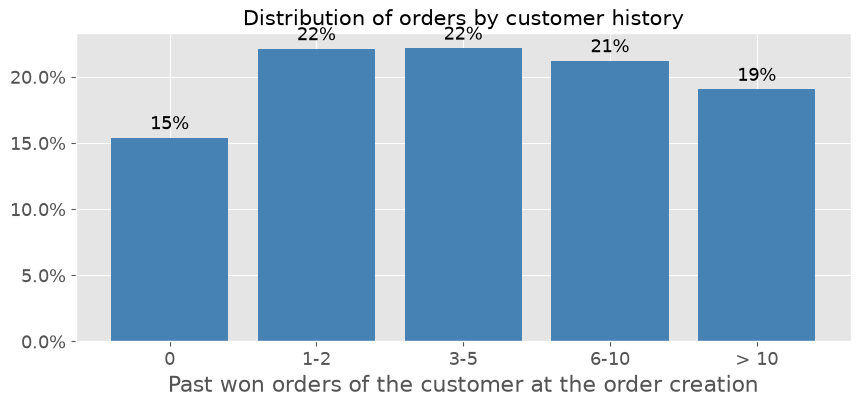

Orders without any past win: 15.4%


In [7]:
dataset_aux = pd.cut(pedidos["n_pedidos_ganhos"], [-1, 0, 2, 5, 10, 1000],
                     labels=["0", "1-2", "3-5", "6-10", "> 10"]).value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(dataset_aux.index.astype(str), dataset_aux.values, color="steelblue")
ax.bar_label(barras, labels=[f"{v:.0%}" for v in dataset_aux.values], padding=3)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Past won orders of the customer at the order creation")
ax.set_title("Distribution of orders by customer history")
plt.show()

print(f"Orders without any past win: {(pedidos['n_pedidos_ganhos'] == 0).mean():.1%}")

About **15% of the orders come from customers without any past win** at the moment of the order (new customers or customers that only lost until then). With `dropna()` all of them would be thrown away; here they stay, and the model can learn that "no history" is itself informative.

## 3. Time of the order: fixing the leakage
In the original model, the most important variable was:

$$\text{ratio\_geral} = \frac{\text{tempo\_pedido}}{\text{average time of the past orders of the customer}}$$

where `tempo_pedido` was:

- for **closed** orders (training): the number of days between the creation and the **outcome**;
- for **open** orders (prediction): the number of days between the creation and **today**.

These are two different things with the same name. In the training, the model learns that "orders that took a long time are lost" (true, notebook 02 showed it), but the time it sees is the **final** time, which only exists after the outcome. An order that is open for 5 days today is not comparable with an order that was lost after 40 days. The variable is a mix of predictor and answer.

### The fix: snapshots
The question that the model really answers in production is: *"this order has been open for **k** days; what is the chance that it will be lost?"*. So the training should look like that too. Each closed order is "photographed" at several ages (0, 7, 14, 21, 28, 45 and 60 days), **while it was still open**:

| Order | Closed after | Rows in the training |
|-------|--------------|----------------------|
| A (won) | 10 days | ages 0 and 7 |
| B (lost) | 40 days | ages 0, 7, 14, 21 and 28 |

In each row, the time variables are calculated with the **age of the snapshot**, exactly like an open order in production:

$$\text{idade\_pedido} = k \qquad \text{ratio\_tempo} = \frac{k}{\text{average time of the past orders of the customer}}$$

The fact that "orders that stay open for a long time are lost more" is still learned, but now in a legitimate way: an order only reaches age 28 in the training if it was really still open at day 28.

In [8]:
IDADES = [0, 7, 14, 21, 28, 45, 60]

base_fechados = pedidos[pedidos["perda"].notna()]
snapshots = []
for k in IDADES:
    # an order enters the age k snapshot only if it was still open at that age
    ainda_aberto = base_fechados[(base_fechados["tempo_pedido"] > k) | (k == 0)].copy()
    ainda_aberto["idade_pedido"] = k
    snapshots.append(ainda_aberto)

snapshots = pd.concat(snapshots, ignore_index=True)
snapshots["ratio_tempo"] = np.where(snapshots["media_tempo_pedido"] > 0,
                                    snapshots["idade_pedido"] / snapshots["media_tempo_pedido"], np.nan)

dataset_aux = snapshots.groupby("idade_pedido", as_index=False).agg(linhas=("perda", "size"), taxa_perda=("perda", "mean"))
dataset_aux

,idade_pedido,linhas,taxa_perda
0,0,18561,0.385162
1,7,14134,0.445946
2,14,8622,0.550916
3,21,4732,0.705199
4,28,2699,0.828825
5,45,786,0.968193
6,60,281,0.985765


Each age has fewer rows than the previous one, because the orders that already closed leave the base. And the loss rate of the orders that are **still open** grows quickly with the age: 38% at creation, 55% at two weeks and 83% at four weeks. An order that is still open after a month is, most of the time, an order that the customer already gave up and nobody marked yet.

This is the information that `ratio_geral` was trying to capture, now available without looking into the future.

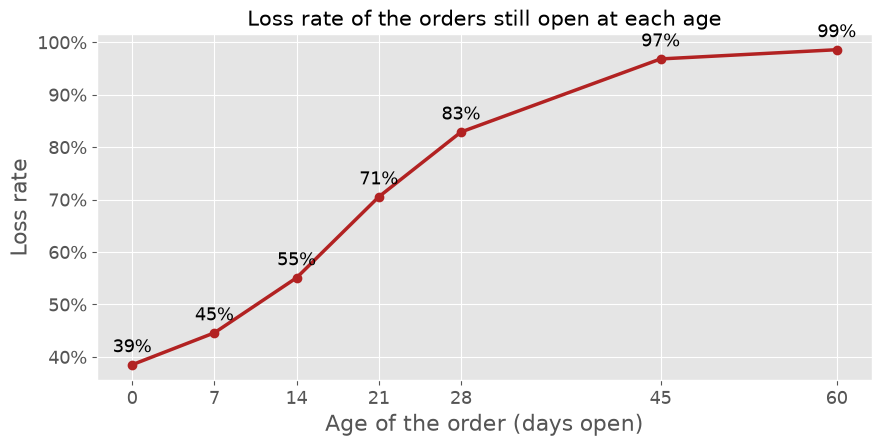

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(dataset_aux["idade_pedido"], dataset_aux["taxa_perda"], marker="o", linewidth=2.5, color="firebrick")
for _, linha in dataset_aux.iterrows():
    ax.annotate(f"{linha['taxa_perda']:.0%}", (linha["idade_pedido"], linha["taxa_perda"]), textcoords="offset points", xytext=(0, 9), ha="center")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xticks(IDADES)
ax.set_xlabel("Age of the order (days open)")
ax.set_ylabel("Loss rate")
ax.set_title("Loss rate of the orders still open at each age")
plt.show()

For comparison, the original variable is also kept in the order base (`ratio_geral`, with the final time of the order), so that notebook 04 can show what happens with a model trained with it.

In [10]:
pedidos["ratio_geral"] = np.where(pedidos["media_tempo_pedido"] > 0, pedidos["tempo_pedido"] / pedidos["media_tempo_pedido"], np.nan)

# the open orders are the ones that will be scored: their age is the time elapsed until the reference date
abertos = pedidos[pedidos["Status_Pedido"] == "Aberto"].copy()
abertos["idade_pedido"] = (DATA_REF - abertos["DataCriacaoId"]).dt.days
abertos["ratio_tempo"] = np.where(abertos["media_tempo_pedido"] > 0, abertos["idade_pedido"] / abertos["media_tempo_pedido"], np.nan)

print(f"Order base (closed): {pedidos['perda'].notna().sum():,} rows")
print(f"Snapshot base:       {len(snapshots):,} rows")
print(f"Open orders:         {len(abertos):,} rows")

Order base (closed): 18,561 rows
Snapshot base:       49,815 rows
Open orders:         384 rows


## Saving

In [11]:
pedidos.drop(columns=["mes_ref"]).to_parquet(PASTA_DADOS / "base_pedidos.parquet", index=False)
snapshots.drop(columns=["mes_ref"]).to_parquet(PASTA_DADOS / "base_snapshots.parquet", index=False)
abertos.drop(columns=["mes_ref"]).to_parquet(PASTA_DADOS / "base_abertos.parquet", index=False)

In [12]:
#Cleaning the environment
import gc
del itens, pedidos, fechados, historico, ind_fechados, ind_ganhos, ganhos, ref_uf, snapshots, base_fechados, abertos, dataset_aux
gc.collect();